Predicting survival in the ICU

In [6]:
library(readr); library(dplyr); library(ggplot2)
library(repr); library(rpart); library(rpart.plot)
options(repr.plot.width=9, repr.plot.height=6)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [13]:
ICU <- read.csv("/Users/emilyahmad/DataScience/OM065-Data-Science/Data/ICU.csv")

ICU$DangerBP <- 0
ICU$DangerBP[ICU$SysBP>140] <- 1

In [14]:
table(ICU$Survive)
mean(ICU$Survive)


  0   1 
 40 160 

[1] 0.8

In [15]:
index <- sample(nrow(ICU), nrow(ICU)*0.8)
ICU_train <- ICU[index, ]
ICU_test  <- ICU[-index, ]

In [16]:
library(caret)
prop.index <- createDataPartition(ICU$Survive, p = 0.8, list = FALSE, times = 1)
ICU.train <- ICU[prop.index, ]
ICU.test  <- ICU[-prop.index, ]

Loading required package: lattice



In [17]:
tree <- rpart(Survive ~ Age + Sex + Infection + Pulse + DangerBP + Emergency,
              data = ICU_train, method = "class", cp = 0.00001)

ERROR: Error in apply(model$frame$yval2[, yval2per], 1, function(x) x[1 + x[1]]): dim(X) must have a positive length


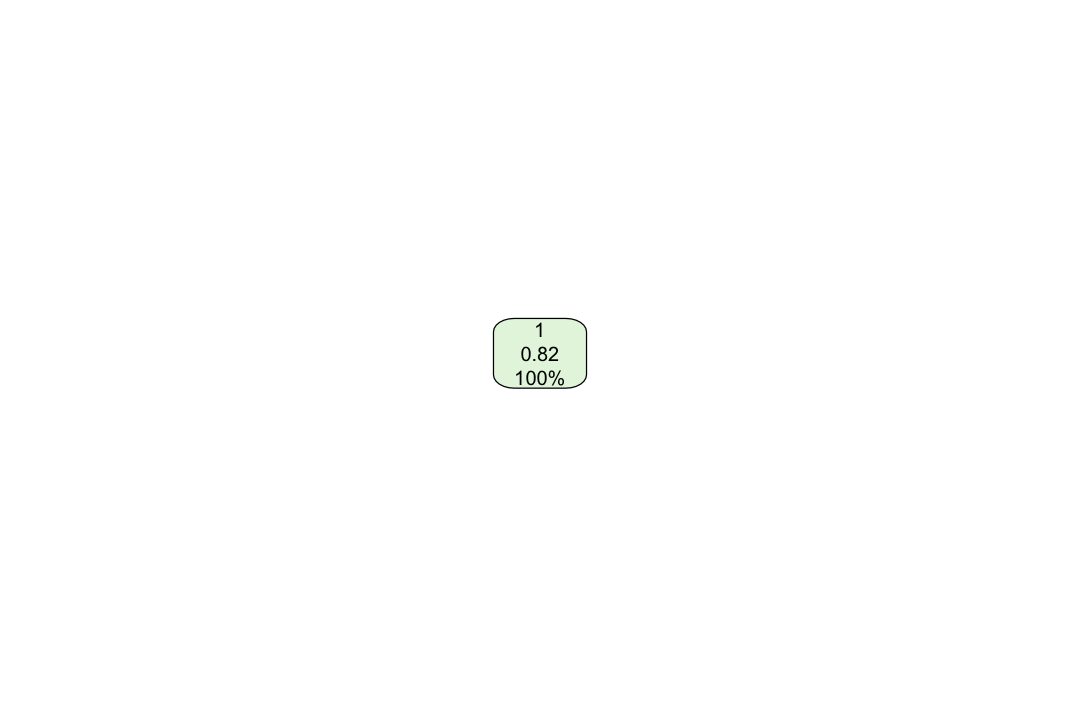

In [41]:
par(mfrow = c(1, 1)); rpart.plot(tree)
library(rattle); fancyRpartPlot(tree); fancyRpartPlot(tree, tweak=1.5)

In [42]:
predicted <- predict(tree, ICU.train, type = "class")
table(predicted, ICU.train$Survive)
mean(predicted == ICU.train$Survive)

         
predicted   0   1
        0   0   0
        1  28 132

[1] 0.825

In [20]:
test.prediction <- predict(tree, ICU.test, type = "class")
table(test.prediction, ICU.test$Survive)
mean(test.prediction == ICU.test$Survive, na.rm=TRUE)

               
test.prediction  0  1
              0  4  2
              1  8 26

[1] 0.75

In [21]:
logistic <- glm(Survive ~ Age + Sex + Emergency + Infection + Pulse + DangerBP,
                data = ICU.train, family = binomial)
summary(logistic)


Call:
glm(formula = Survive ~ Age + Sex + Emergency + Infection + Pulse + 
    DangerBP, family = binomial, data = ICU.train)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept)  4.927927   1.298177   3.796 0.000147 ***
Age         -0.035250   0.013470  -2.617 0.008873 ** 
Sex          0.111358   0.460063   0.242 0.808741    
Emergency   -2.187751   0.800289  -2.734 0.006263 ** 
Infection   -0.085886   0.493860  -0.174 0.861938    
Pulse        0.003020   0.008578   0.352 0.724748    
DangerBP     0.818913   0.531744   1.540 0.123548    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 148.39  on 159  degrees of freedom
Residual deviance: 125.92  on 153  degrees of freedom
AIC: 139.92

Number of Fisher Scoring iterations: 6


In [22]:
ICU.train$Predicted <- fitted(logistic)

In [23]:
threshold <- 0.99
ICU.train$PredictSurvive <- ifelse(ICU.train$Predicted >= threshold, 1, 0)
summary(ICU.train$Predicted)
cor(ICU.train$Survive, ICU.train$Predicted)
addmargins(table(ICU.train$Survive))
mean(ICU.train$PredictSurvive == ICU.train$Survive)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.4141  0.7113  0.8641  0.8250  0.9479  0.9911 

[1] 0.3747753


  0   1 Sum 
 28 132 160 

[1] 0.1875

In [26]:
n <-100
accuracy <- c()
thresholds <- c()
for (i in 0:n) {
threshold = i/n
PredictSurvive <- ifelse(ICU.train$Predicted >= threshold, 1, 0)
accuracy[i] <- (addmargins(table(ICU.train$Survive,PredictSurvive))[1,1] +
addmargins(table(ICU.train$Survive,PredictSurvive))[2,2]) /
length(PredictSurvive)
thresholds[i] <- i/n
}
df <- na.omit(data.frame(thresholds, accuracy))
df <- df[df$accuracy<1,]
threshold.opt <- df$thresholds[which.max(df$accuracy)]
threshold.opt

[1] 0.46

In [29]:
ICU.test$Predicted <- predict(logistic, newdata = ICU.test, type = "response")
ICU.test$PredictSurvive <- ifelse(ICU.test$Predicted >= threshold.opt, 1, 0)
t.test <- table(ICU.test$Survive, ICU.test$PredictSurvive)
addmargins(t.test); mean(ICU.test$PredictSurvive == ICU.test$Survive)

,1,Sum
0,12,12
1,28,28
Sum,40,40


[1] 0.7


Classification tree:
rpart(formula = Survive ~ Age + Sex + Infection + Pulse + DangerBP + 
    Emergency, data = ICU.train, method = "class", cp = 0.01)

Variables actually used in tree construction:
[1] Age       DangerBP  Emergency Pulse     Sex      

Root node error: 28/160 = 0.175

n= 160 

        CP nsplit rel error xerror    xstd
1 0.014286      0   1.00000 1.0000 0.17165
2 0.010000      5   0.92857 1.6071 0.20311


         
predicted   0   1
        0   0   0
        1  28 132

[1] 0.825

               
test.prediction  0  1
              0  0  0
              1 12 28

[1] 0.7

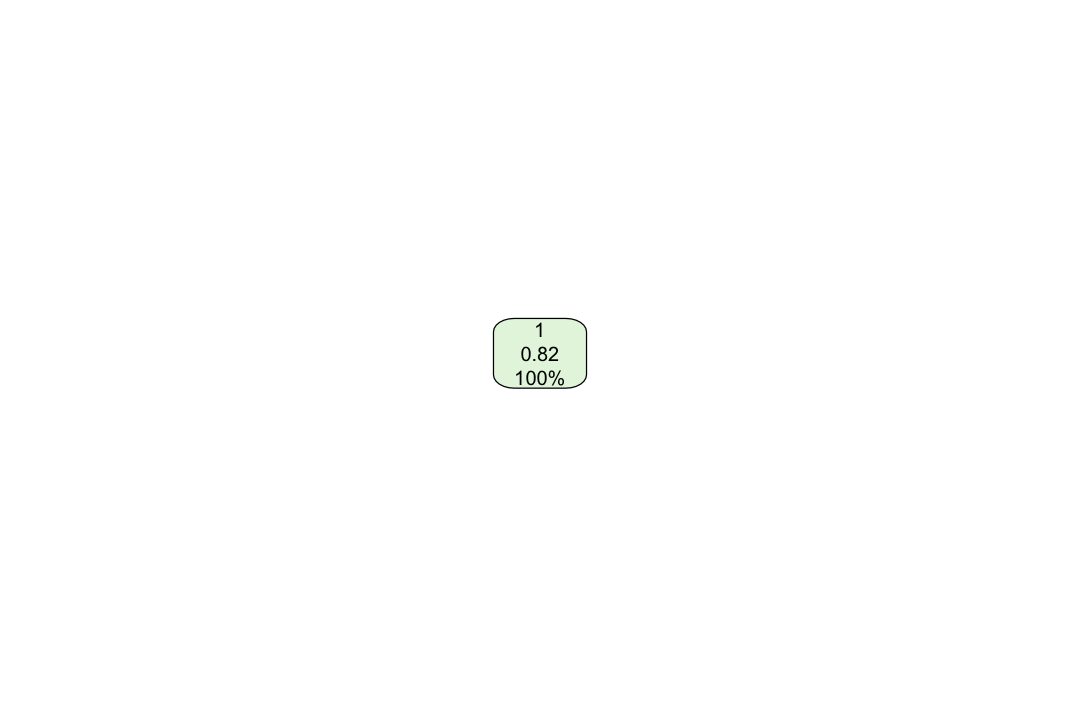

In [49]:
tree <- rpart(Survive ~ Age + Sex + Infection + Pulse + DangerBP + Emergency,
              data = ICU.train, method = "class", cp = 0.01)
printcp(tree)
best_cp <- tree$cptable[which.min(tree$cptable[, "xerror"]), "CP"]
tree <- prune(tree, cp = best_cp)
rpart.plot(tree)
predicted <- predict(tree, ICU.train, type = "class")
table(predicted, ICU.train$Survive)
mean(predicted == ICU.train$Survive)
test.prediction <- predict(tree, ICU.test, type = "class")
table(test.prediction, ICU.test$Survive)
mean(test.prediction == ICU.test$Survive)

In [32]:
install.packages("randomForest")
library(randomForest)
set.seed(111)


The downloaded binary packages are in
	/var/folders/rk/hm976cm116b00fkw44hrlkgc0000gn/T//RtmpQyF5fS/downloaded_packages


randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Attaching package: ‘randomForest’


The following object is masked from ‘package:ggplot2’:

    margin


The following object is masked from ‘package:dplyr’:

    combine




In [33]:
summary(is.na(ICU) == TRUE)

     ID           Survive           Age           AgeGroup      
 Mode :logical   Mode :logical   Mode :logical   Mode :logical  
 FALSE:200       FALSE:200       FALSE:200       FALSE:200      
    Sex          Infection         SysBP           Pulse        
 Mode :logical   Mode :logical   Mode :logical   Mode :logical  
 FALSE:200       FALSE:200       FALSE:200       FALSE:200      
 Emergency        DangerBP      
 Mode :logical   Mode :logical  
 FALSE:200       FALSE:200      

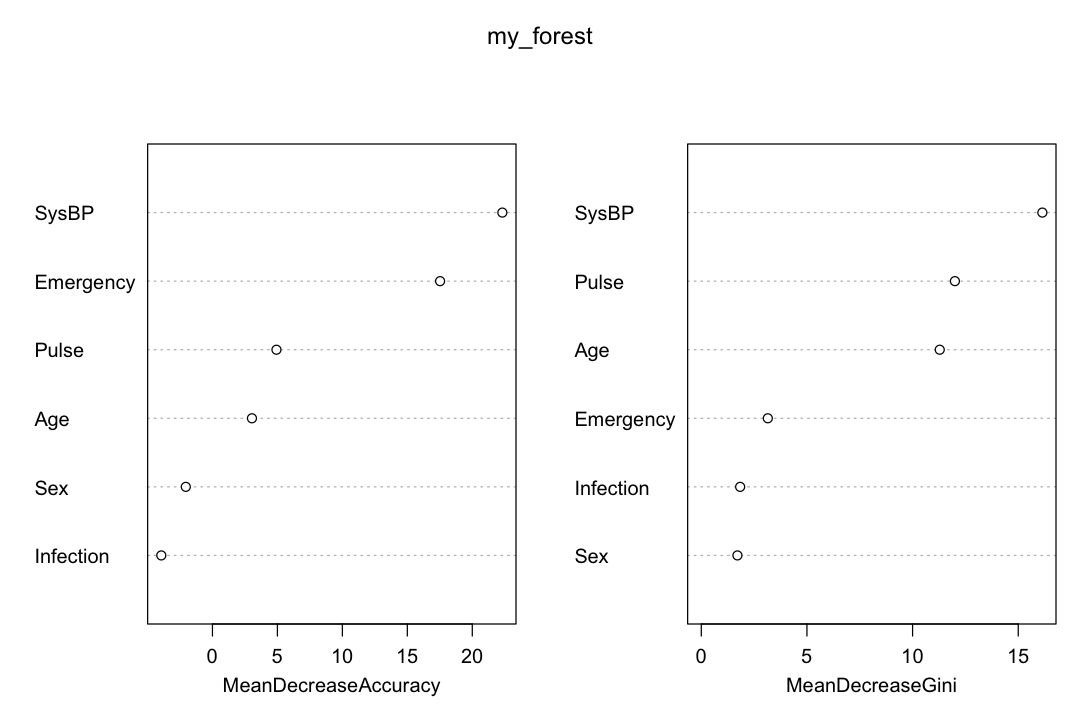

In [34]:

my_forest <- randomForest(factor(Survive) ~ Age + Sex + Infection + SysBP + Pulse + Emergency,
                          data = ICU_train, importance = TRUE, ntree = 1000)
varImpPlot(my_forest)

In [35]:
my_prediction <- predict(my_forest, ICU.test, type = "class")
addmargins(table(my_prediction, ICU.test$Survive))
round(mean(my_prediction == ICU.test$Survive, na.rm=TRUE), 3)

,0,1,Sum
0,10,0,10
1,2,28,30
Sum,12,28,40


[1] 0.95

In [44]:
# in sample & out of sample accuracy